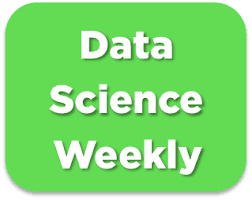

# Import libraries

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge, Lasso
from sklearn.model_selection import cross_val_score, KFold, GridSearchCV
from sklearn.metrics import r2_score
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
)
from sklearn.model_selection import cross_val_score

import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings(
    "ignore", category=DeprecationWarning
)  # to avoid deprecation warnings

import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

from IPython.display import display

# Read file with labels

In [2]:
df = pd.read_csv("walmart_sales.csv")

df2 is ready to preprocess with sklearn.

# preprocessing pandas

In [3]:
df.columns = df.columns.str.lower()
print(df.columns)

Index(['store', 'date', 'weekly_sales', 'holiday_flag', 'temperature',
       'fuel_price', 'cpi', 'unemployment'],
      dtype='str')


In [4]:
print('Missing values treatment...')
cols = ['weekly_sales', 'date']
df = df.dropna(subset=cols) # drop lines where target values is missing. 

Missing values treatment...


In [5]:
categories = ['store', 'holiday_flag']

df[categories] = df[categories].astype('Int64') # convert categories in integers, avoid error "Cannot convert non-finite values".

In [6]:
print(df.dtypes)

store             Int64
date                str
weekly_sales    float64
holiday_flag      Int64
temperature     float64
fuel_price      float64
cpi             float64
unemployment    float64
dtype: object


In [7]:
# Conversion des dates au format date time
type('date')
df['date'] = pd.to_datetime(df['date'], format = "%d-%m-%Y")
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['day'] = df['date'].dt.day
df['weekday'] = df['date'].dt.dayofweek
print(df['weekday'].value_counts(dropna=False))

weekday
4    118
Name: count, dtype: int64


In [8]:
numerical_cols = ['fuel_price', 'cpi', 'unemployment']
df[numerical_cols] = df[numerical_cols].round(2)
print(df[categories + ['date']].dtypes)

store                    Int64
holiday_flag             Int64
date            datetime64[us]
dtype: object


In [9]:
# Preprocessing
## preprocessing pandas
df=df.drop('date', axis=1)
df.head(1)

,store,weekly_sales,holiday_flag,temperature,fuel_price,cpi,unemployment,year,month,day,weekday
0,6,1572117.54,<NA>,59.61,3.04,214.78,6.86,2011,2,18,4


In [10]:
mean = df['unemployment'].mean()
sigma = df['unemployment'].std()

mask = df['unemployment'].between(mean - 3 * sigma, mean + 3 * sigma)
df = df[mask]
print(df.shape)

(102, 11)


In [11]:
### drop store 11
count = df['store'].value_counts()
count[count < 2]
mask = df['store'].isin(count[count < 2].index)
df = df.drop(df[mask].index)
df.head(1)

,store,weekly_sales,holiday_flag,temperature,fuel_price,cpi,unemployment,year,month,day,weekday
0,6,1572117.54,<NA>,59.61,3.04,214.78,6.86,2011,2,18,4


In [12]:
print(df['store'].value_counts().sort_index())

store
1      7
2      5
3     10
4      6
5      6
6      6
7      7
8      5
9      3
10     3
13     9
14     7
15     2
16     4
17     3
18     6
19     8
20     4
Name: count, dtype: Int64


In [13]:
df.shape

(101, 11)

## preprocessing with sklearn

### Multivariate linear regression

#### Separate target variable Y from features X

In [14]:
# Separate target variable Y from features X

print("Separating labels from features...")
target = 'weekly_sales'

y = df.loc[:, target]# or df.iloc[:, -1] # or  df.loc[:, df.columns == target]
X = df.drop(target, axis=1) # or df.iloc[:, 0:-1]  # All columns are kept, except the target
# or df.loc[:, df.columns != target]
print("...Done.")

print("y : ")
print(y.head())
print()
print("X : ")
print(X.head())

Separating labels from features...
...Done.
y : 
0    1572117.54
1    1807545.43
4    1644470.66
5    1857533.70
6     695396.19
Name: weekly_sales, dtype: float64

X : 
   store  holiday_flag  temperature  fuel_price     cpi  unemployment  year  \
0      6          <NA>        59.61        3.04  214.78          6.86  2011   
1     13             0        42.38        3.44  128.62          7.47  2011   
4      6             0        78.89        2.76  212.41          7.09  2010   
5      4             0          NaN        2.76  126.16          7.90  2010   
6     15             0        69.80        4.07  134.86          7.66  2011   

   month  day  weekday  
0      2   18        4  
1      3   25        4  
4      5   28        4  
5      5   28        4  
6      6    3        4  


In [15]:
numeric_features = ['temperature', 'fuel_price', 'cpi', 'unemployment']
categorical_features = ['store', 'holiday_flag']

Remember to treat year, 'month', 'day', 'weekday' as numeric features (cf instructions)

#### Divide dataset train set & test set 

We apply different transformations to the features, depending on their types. Numeric columns will be standardized whereas categorical columns will be one-hot-encoded. As regards missing values imputation, it can apply to every column, but different rules may be used. 

In [16]:
# Divide dataset Train set & Test set
print("Dividing into train and test sets...")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=X['store']
)
print("...Done.")
print()

Dividing into train and test sets...
...Done.



We'll use simple imputer because we don't have any missing values. num_imputer = SimpleImputer(strategy="median")

We normalize numeric colomns to scale them down.

#### pipelines

In [17]:
print("Preprocessing X_train...")
print(X_train.head())
print()

# categoric

cat_transformer = Pipeline(steps=[
    ('cat_imputer', SimpleImputer(strategy="most_frequent")),
    ('catEncoder', OneHotEncoder(drop='first', handle_unknown='ignore')) # avoid 
])
# numerical

num_transformer = Pipeline(steps=[
    ('num_imputer', SimpleImputer(strategy="median")),
    ('scaler', StandardScaler())
])

#### pipeline global
print("Encoding categorical features and standardizing numerical features...")

preprocessor = ColumnTransformer(transformers=[
    ('cat_transformer', cat_transformer, categorical_features),
    ('num_transformer', num_transformer, numeric_features)
])

# # Preprocessings on train set
# print("Preprocessing sur le train set...")
# X_train = preprocessor.fit_transform(X_train)
# print('...Terminé.')
# X_train[0:5] # MUST use this syntax because X_train is a numpy array and not a pandas DataFrame anymore

Preprocessing X_train...
     store  holiday_flag  temperature  fuel_price     cpi  unemployment  year  \
128     13             0        75.95        3.61  129.20          6.88  2011   
123      1             0          NaN        3.79  215.50          7.68  2011   
12       7             0        36.61        3.77  192.83          8.60  2011   
141      5             0        62.37         NaN  212.56          6.77  2010   
113     13             0        32.71         NaN  130.28          6.10  2012   

     month  day  weekday  
128      8   12        4  
123      5   27        4  
12       5   13        4  
141     11   12        4  
113      1   20        4  

Encoding categorical features and standardizing numerical features...


In [18]:
print('X_train')
X_train.dtypes

X_train


store             Int64
holiday_flag      Int64
temperature     float64
fuel_price      float64
cpi             float64
unemployment    float64
year              int32
month             int32
day               int32
weekday           int32
dtype: object

In [19]:
print(X_train['store'].value_counts().sort_index())

store
1     5
2     3
3     7
4     4
5     4
6     4
7     5
8     4
9     2
10    2
13    6
14    5
15    1
16    3
17    2
18    4
19    6
20    3
Name: count, dtype: Int64


In [25]:
### Cross-validated score for a Ridge model L2 (with default value of λλ)

# Perform 3-fold cross-validation to evaluate the generalized R2 score obtained with a Ridge model
cv = KFold(n_splits=2, shuffle=True, random_state=42)

### Grid search : tune λλ
# Perform grid search
print("Grid search...")

models = {"Ridge (L2)": Ridge(), "Lasso (L1)": Lasso(max_iter=10000)}
alpha = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1, 10, 25, 50, 80, 90, 100, 110, 125, 130, 138, 140, 141, 142, 143, 145, 150, 160, 180, 190, 200, 205, 209, 210, 211, 212, 213, 215, 225, 275, 279, 280, 281, 285, 290, 300, 400, 500, 1000, 10000, 100000]

# Grid of values to be tested
params = {
    "Linear Regression": [{}], # tester une seule configuration avec les paramètres par défaut de LinearRegression 
    "Ridge (L2)": {"model__alpha": alpha},
    "Lasso (L1)": {"model__alpha": alpha}
}
models = {
    "Linear Regression": LinearRegression(),
    "Ridge (L2)": Ridge(),
    "Lasso (L1)": Lasso(max_iter=10000)
}

for name, regressor in models.items():
    pipeline_lr = Pipeline(steps=[('preprocessor', preprocessor), ('model', regressor)])
    param_grid = {} if name == "Linear Regression" else params
    gridsearch = GridSearchCV(pipeline_lr, param_grid=param_grid, scoring='r2', cv=5, n_jobs=-1)
    gridsearch.fit(X_train, y_train)
    # ... reste du code

Grid search...


TypeError: Parameter grid for parameter 'Ridge (L2)' needs to be a list or a numpy array, but got {'model__alpha': [1e-05, 0.0001, 0.001, 0.01, 0.1, 1, 10, 25, 50, 80, 90, 100, 110, 125, 130, 138, 140, 141, 142, 143, 145, 150, 160, 180, 190, 200, 205, 209, 210, 211, 212, 213, 215, 225, 275, 279, 280, 281, 285, 290, 300, 400, 500, 1000, 10000, 100000]} (of type dict) instead. Single values need to be wrapped in a list with one element.

In [ ]:
### Cross-validated score for a Ridge model L2 (with default value of λλ)

# Perform 3-fold cross-validation to evaluate the generalized R2 score obtained with a Ridge model
cv = KFold(n_splits=2, shuffle=True, random_state=42)

'''print("3-fold cross-validation...")
scores = cross_val_score(regressor, X_train, y_train, cv=5)
print('The cross-validated R2-score is : ', scores.mean())
print('The standard deviation is : ', scores.std())'''

### Grid search : tune λλ
# Perform grid search
print("Grid search...")

models = {"Ridge (L2)": Ridge(), "Lasso (L1)": Lasso(max_iter=10000)}

# Grid of values to be tested
params = {"model__alpha": [1e-05, 1e-04, 1e-03, 1e-02, 1e-01, 0.01, 0.02, 0.5, 0.3, 0.2, 0.1, 1, 10, 25, 50, 80, 90, 100, 110, 125, 130, 138, 140, 141, 142, 143, 145, 150, 160, 180, 190, 200, 205, 209, 210, 211, 212, 213, 215, 225, 275, 279, 280, 281, 285, 290, 300, 400, 500, 1000, 10000, 100000] # linearRegression
}

for name, regressor in models.items():
    pipeline_lr = Pipeline(steps=[('preprocessor', preprocessor), ('model', regressor)])
    gridsearch = GridSearchCV(pipeline_lr, param_grid=params, scoring='r2', error_score='raise', cv=5, n_jobs=-1)
    gridsearch.fit(X_train, y_train)

    print(name)
    print("Best alpha : ", gridsearch.best_params_)
    print("Best R2 score : ", gridsearch.best_score_)
    print("R2 train   :", gridsearch.score(X_train, y_train))
    print("R2 test    :", gridsearch.score(X_test, y_test))
    print()
print('Done...')


Nous n'utilisons pas labelEncoder sur y_test car les labels sont déjà convertis sur converted

#### Test pipeline

In [ ]:
# Preprocessings sur le test set
print("Preprocessing on test set...")
X_test = preprocessor.transform(X_test) # Don't fit again !! The test set is used for validating decisions
# we made based on the training set, therefore we can only apply transformations that were parametered using the training set.
# Otherwise this creates what is called a leak from the test set which will introduce a bias in all your results.
print('...Done.')
X_test[:5, :] # MUST use this syntax because X_test is a numpy array and not a pandas DataFrame anymore

#### Train model

In [ ]:

from sklearn.linear_model import LinearRegression

print("Train model...")
regressor = LinearRegression() # 
regressor.fit(X_train, y_train)
print("...Done.")

In [ ]:
type(X_train)

#### Performance evaluation

#### Predictions

In [ ]:
# Predictions on training set
print("Predictions on training set...")
y_train_pred = regressor.predict(X_train)
print("...Done.")
print(y_train_pred)
print()

In [ ]:
# Predictions on test set
print("Predictions on test set...")
y_test_pred = regressor.predict(X_test)
print("...Done.")
print(y_test_pred)
print()

# Fight over-fitting

# Cross validation ridge et lasso

In [ ]:
X_train_missing_values = X_train.isnull().sum()/df.shape[0]*100

In [ ]:
print(X_train_missing_values)

In [ ]:
### Cross-validated score for a Ridge model L2 (with default value of λλ)

### Grid search : tune λλ
# Perform grid search
print("Grid search...")
regressor = LinearRegression()

pipeline_lr = Pipeline([
    ("preprocessor", preprocessor),
    ("model", regressor),
])

params = {"model__alpha": [0.01, 0.1, 1, 10, 100, 1000]}
models = {"Ridge (L2)": Ridge(), "Lasso (L1)": Lasso(max_iter=10000)}

for name, reg in models.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('model', reg)])
    grid = GridSearchCV(pipe, param_grid=params, scoring='r2', cv=5, error_score='raise', n_jobs=-1)
    grid.fit(X_train, y_train)
    print(name)
    print("Best alpha :", grid.best_params_)
    print("R2 CV      :", grid.best_score_)
    print("R2 train   :", grid.score(X_train, y_train))
    print("R2 test    :", grid.score(X_test, y_test))
    print()

In [ ]:
# Perform 3-fold cross-validation to evaluate the generalized R2 score obtained with a Ridge model
print("3-fold cross-validation...")
scores = cross_val_score(regressor, X_train, y_train, cv=5)
print('The cross-validated R2-score is : ', scores.mean())
print('The standard deviation is : ', scores.std())

Tune lambda

In [ ]:
ridge_best = Ridge(alpha=gridsearch.best_params_["alpha"])
ridge_best.fit(X_train, y_train)
print("R2 train :", ridge_best.score(X_train, y_train))
print("R2 test :", ridge_best.score(X_test, y_test))

Interpreting the models coefficients

In [ ]:
regressor.coef_

In [ ]:
column_names = []
for name, pipeline, features_list in preprocessor.transformers_: # loop over pipelines
    if name == 'num_transformer': # if pipeline is for numeric variables
        features = features_list # just get the names of columns to which it has been applied
    else: # if pipeline is for categorical variables
        features = pipeline.named_steps['catEncoder'].get_feature_names_out() # get output columns names from OneHotEncoder
    column_names.extend(features) # concatenate features names

print("Names of columns corresponding to each coefficient: ", column_names)

In [ ]:
# Create a pandas DataFrame
coefs = pd.DataFrame(index = column_names, data = regressor.coef_.transpose(), columns=["coefficients"])
coefs

In [ ]:
# Compute abs() and sort values
feature_importance = abs(coefs).sort_values(by = 'coefficients')
feature_importance

In [ ]:
# Plot coefficients
fig = px.bar(feature_importance, orientation = 'h')
fig.update_layout(showlegend = False,
                  margin = {'l': 120} # to avoid cropping of column names
                 )
fig.show()

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(y_test, y_test_pred)
plt.xlabel("Valeurs réelles")
plt.ylabel("Valeurs prédites")
plt.show()

In [ ]:
plt.scatter(y_test, y_test_pred)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red")
plt.xlabel("Valeurs réelles")
plt.ylabel("Valeurs prédites")
plt.show()

In [ ]:
lim_max = max(y_test.max(), y_test_pred.max())

plt.scatter(y_test, y_test_pred)
plt.plot([0, lim_max], [0, lim_max], color="red")
plt.xlim(0, lim_max)
plt.ylim(0, lim_max)
plt.xlabel("Valeurs réelles")
plt.ylabel("Valeurs prédites")
plt.show()

In [ ]:
# Perform 3-fold cross-validation to evaluate the generalized R2 score obtained with a Ridge model
print("3-fold cross-validation...")

scores = cross_val_score(regressor, X_train, y_train, cv=5)
print('The cross-validated R2-score is : ', scores.mean())
print('The standard deviation is : ', scores.std())

Extract the coefficients of each of the three Ridge models, and store them into a DataFrame

In [ ]:
column_names = list(preprocessor.get_feature_names_out())
print(len(column_names), column_names)

Plot the coefficients of the three models in the same figure.

In [ ]:
fig = px.line(coefficients_ridge, x = 'Feature', y = ['Ridge1', 'Ridge2', 'Ridge3', 'Ridge4' ])
fig.show()

In [ ]:
# Print R^2 scores
print("R2 score on training set : ", gridsearch.score(X_train, y_train))
print("R2 score on test set : ", gridsearch.score(X_test, y_test))

la régularisation n'améliore pas le modèle, car il y a peu de variables et beaucoup de données

Lasso

### hyperparameter optimization

In [ ]:
# Perform grid search
print("Grid search...")
regressor = Ridge()
# Grid of values to be tested
params = {
    'alpha': [0.01, 0.05, 0.1, 0.5, 1, 5, 10, 25, 45.74, 45.75, 45.76, 50, 75, 100]
}
best_ridge = GridSearchCV(regressor, param_grid = params, cv = 10) # cv : the number of folds to be used for CV
best_ridge.fit(X_train, y_train)
print("...Done.")
print("Best hyperparameters : ", best_ridge.best_params_)
print("Best R2 score : ", best_ridge.best_score_)

In [ ]:
# Perform grid search
print("Grid search...")
regressor = Lasso()
# Grid of values to be tested
params = {
    'alpha': [1e-10, 1e-07, 1e-06, 1e-05, 1, 2, 3, 5, 10, 20, 30]
}
best_lasso = GridSearchCV(regressor, param_grid = params, cv = 10) # cv : the number of folds to be used for CV
best_lasso.fit(X_train, y_train)
print("...Done.")
print("Best hyperparameters : ", best_lasso.best_params_)
print("Best R2 score : ", best_lasso.best_score_)

In [ ]:
### Comparing models

In [ ]:
# Print R^2 scores
print("RIDGE / R2 score on training set : ", best_ridge.score(X_train, y_train))
print("RIDGE / R2 score on test set : ", best_ridge.score(X_test, y_test))
print()
print("LASSO / R2 score on training set : ", best_lasso.score(X_train, y_train))
print("LASSO / R2 score on test set : ", best_lasso.score(X_test, y_test))

In [ ]:
data_dict = {
    'Feature': list(preprocessor.get_feature_names_out()),
    'Best_Ridge': best_ridge.best_estimator_.coef_,
    'Best_Lasso': best_lasso.best_estimator_.coef_
            }

coefficients = pd.DataFrame(data = data_dict)
coefficients.head()

In [ ]:
fig = px.line(coefficients, x = 'Feature', y = ['Best_Ridge', 'Best_Lasso'])
fig.show()

### Using Lasso as an automated feature selection method

In [ ]:
# Extract the names of the features that have non-zero coefficients in Lasso.
mask = coefficients['Best_Lasso'] != 0
best_features = coefficients.loc[mask, 'Feature'].to_list()
best_features

In [ ]:
best_features = [f.split('__')[1] for f in best_features]   # retire le préfixe
raw_cols = [c for c in X.columns if any(f.startswith(c) for f in best_features)]
print(raw_cols)

X = X.loc[:, raw_cols]

In [ ]:
# Divide dataset Train set & Test set
print("Dividing into train and test sets...")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("...Done.")
print()

In [ ]:
#### pipeline global
print("Encoding categorical features and standardizing numerical features...")

preprocessor = ColumnTransformer(transformers=[
    ('cat_transformer', cat_transformer, categorical_features),
    ('num_transformer', num_transformer, numeric_features)
])

# Preprocessings on train set
print("Preprocessing sur le train set...")
X_train = preprocessor.fit_transform(X_train)
print('...Terminé.')
X_train[0:5] # MUST use this syntax because X_train is a numpy array and not a pandas DataFrame anymore
print()


In [ ]:
# Preprocessings sur le test set
print("Preprocessing on test set...")
X_test = preprocessor.transform(X_test) # Don't fit again !! The test set is used for validating decisions
# we made based on the training set, therefore we can only apply transformations that were parametered using the training set.
# Otherwise this creates what is called a leak from the test set which will introduce a bias in all your results.
print('...Done.')
X_test[:5, :] # MUST use this syntax because X_test is a numpy array and not a pandas DataFrame anymore

In [ ]:
# Train linear regression (no regularization)
print("Train model...")
regressor = LinearRegression()
regressor.fit(X_train, y_train)
print("...Done.")

In [ ]:
pred_train = regressor.predict(X_train)
ths = np.arange(0.1, 0.6, 0.05)
threshold = ths[np.argmax([f1_score(y_train, pred_train > t) for t in ths])]
print(threshold)

In [ ]:
# R2 scores
print("R2 score on training set : ", regressor.score(X_train, y_train))
print("R2 score on test set : ", regressor.score(X_test, y_test))

# Prédictions seuillées à 0.25
y_train_pred = (regressor.predict(X_train) > 0.25).astype(int)
y_test_pred = (regressor.predict(X_test) > 0.25).astype(int)
print(np.unique(y_train_pred))   # doit afficher [0 1]

### Interpreting the model's coefficients

As we've standardized our features, we can use the coefficients of the regression to estimate the importance of each feature for the prediction. The model's parameters are saved in a .coef_ attribute:

In [ ]:
regressor.coef_

In [ ]:
column_names = []
for name, pipeline, features_list in preprocessor.transformers_: # loop over pipelines
    if name == 'num_transformer': # if pipeline is for numeric variables
        features = features_list # just get the names of columns to which it has been applied
    elif name == 'cat_transformer': # if pipeline is for numeric variables
        features = pipeline.named_steps['catEncoder'].get_feature_names_out() # get output columns names from OneHotEncoder
    else:
        continue
    column_names.extend(features) # concatenate features names

print("Names of columns corresponding to each coefficient: ", column_names)

In [ ]:
# Create a pandas DataFrame
coefs = pd.DataFrame(index = column_names, data = regressor.coef_.transpose(), columns=["coefficients"])
coefs

In [ ]:
# Compute abs() and sort values
feature_importance = abs(coefs).sort_values(by = 'coefficients')
feature_importance

In [ ]:
# Plot coefficients
fig = px.bar(feature_importance, orientation = 'h')
fig.update_layout(showlegend = False,
                  margin = {'l': 120} # to avoid cropping of column names
                 )
fig.show()

In [ ]:
# Print scores
print("accuracy on training set : ", accuracy_score(y_train, y_train_pred))
print("accuracy on test set : ", accuracy_score(y_test, y_test_pred))
print()

print("f1-score on training set : ", f1_score(y_train, y_train_pred))
print("f1-score on test set : ", f1_score(y_test, y_test_pred))
print()

In [ ]:
# Visualize confusion matrices
_, ax = plt.subplots()  # Get subplot from matplotlib
ax.set(
    title="Confusion Matrix on Train set"
)  # Set a title that we will add into ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(
    y_train, y_train, ax=ax
)  # ConfusionMatrixDisplay from sklearn
plt.show()

_, ax = plt.subplots()  # Get subplot from matplotlib
ax.set(
    title="Confusion Matrix on Test set"
)  # Set a title that we will add into ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(
    y_test, y_test, ax=ax
)  # ConfusionMatrixDisplay from sklearn
plt.show()

TODO recall et précision